# View BTXRD annotations
Draws the tumor annotation on its X-ray: **red** = tumor outline, **green** = box.
This notebook only reads the data, it never changes it.

In [1]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw

IMAGES = Path("../data/BTXRD dataset/images")
ANNOTATIONS = Path("../data/BTXRD dataset/Annotations")

In [2]:
def draw_annotation(name):
    image = Image.open(next(IMAGES.glob(name + ".*"))).convert("RGB")  # file ends in .jpeg or .jpg
    shapes = json.loads((ANNOTATIONS / (name + ".json")).read_text())["shapes"]

    draw = ImageDraw.Draw(image)
    for shape in shapes:
        points = [tuple(p) for p in shape["points"]]
        if shape["shape_type"] == "polygon":
            draw.polygon(points, outline="red", width=8)
        else:
            (x1, y1), (x2, y2) = points
            draw.rectangle([min(x1, x2), min(y1, y2), max(x1, x2), max(y1, y2)], outline="lime", width=8)

    # Cut away the black border so the X-ray is big enough to see
    ys, xs = np.where(np.array(image.convert("L")) > 10)
    image = image.crop((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1))

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(f"{name}: {shapes[0]['label']}")
    plt.axis("off")
    plt.show()

## Show one image
Change the name to see another one (only tumor images have annotations).

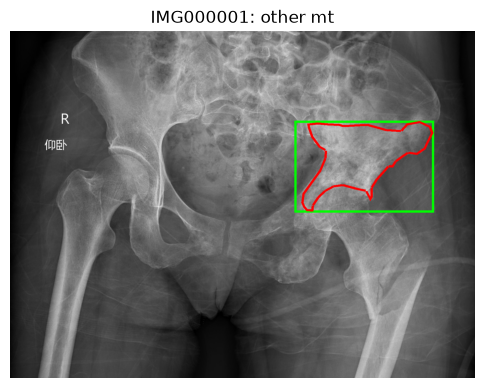

In [6]:
draw_annotation("IMG000001")

## Show 5 random images
Run again to see 5 new ones.

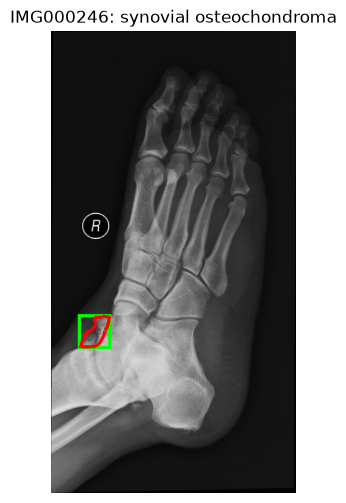

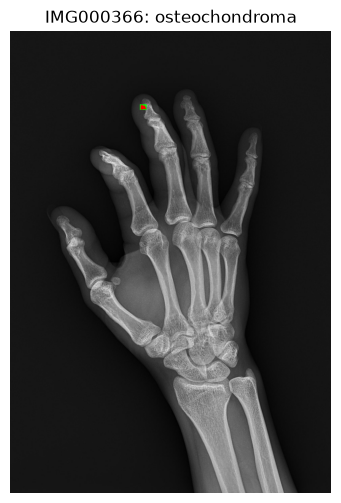

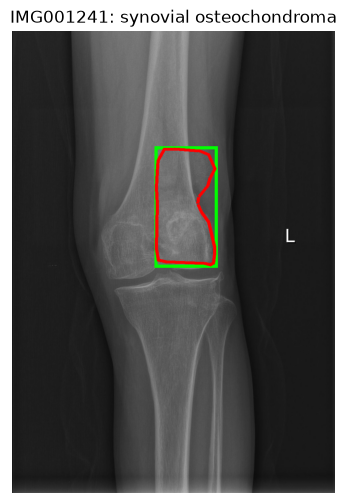

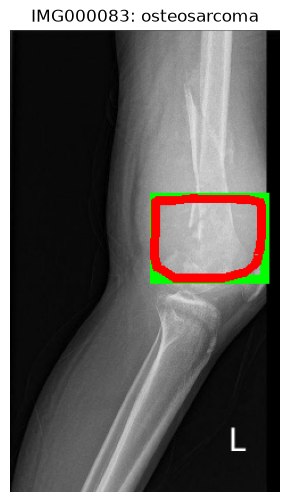

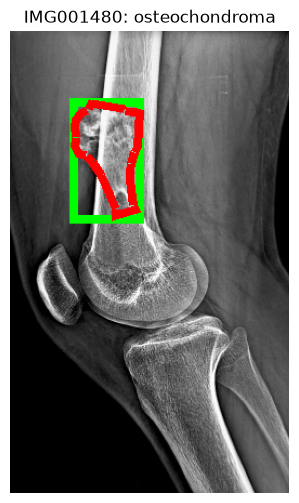

In [7]:
names = [p.stem for p in ANNOTATIONS.glob("*.json")]

for name in random.sample(names, 5):
    draw_annotation(name)